# 🎓 第5章 第1课：F-Score —— 九信号财务体检

**本节目标**：用 Piotroski (2000) 的 F-Score，把“财务健康”变成一个 0~9 分的分数，再看高分股是否跑赢低分股。

对应原书 5.1 节。

> ⚠️ 数据说明：本仓库没有完整财报，F-Score 的九项信号由**教学合成财务面板**生成。
> 本 notebook 演示 F-Score 的计算与排序流程，数值不代表真实公司财务或真实 A 股结论。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.anomalies import (
    make_teaching_fundamentals, piotroski_f_score,
    distance_from_52w_high, rolling_ivol,
)
from factor_zero.factors import build_factor_returns
from factor_zero.sorting import long_short_factor, monotonicity_test, quantile_group, sort_portfolios
from factor_zero.statistics import factor_summary, nw_t_stat

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 1) 九个信号：每一项 1 分

| # | 信号 | 含义 |
|---|---|---|
| 1 | ROA > 0 | 盈利能力为正 |
| 2 | CFO > 0 | 经营现金流为正 |
| 3 | ΔROA > 0 | 盈利能力改善 |
| 4 | CFO > ROA | 利润有现金流支撑（应计质量） |
| 5 | ΔLeverage < 0 | 杠杆下降 |
| 6 | ΔCurrent ratio > 0 | 流动性改善 |
| 7 | 没有增发 | 没有通过增发稀释股东 |
| 8 | ΔGross margin > 0 | 毛利率改善 |
| 9 | ΔAsset turnover > 0 | 资产周转率改善 |

**F-Score = 9 项之和（0~9 分）**。Piotroski 的经典用法：在“高 BM（便宜）”股票里，
买高 F-Score、卖低 F-Score，检验财务健康是否能区分“便宜的好公司”和“价值陷阱”。

F-Score 面板: (83, 81)
有效分数范围: 1.0 ~ 9.0


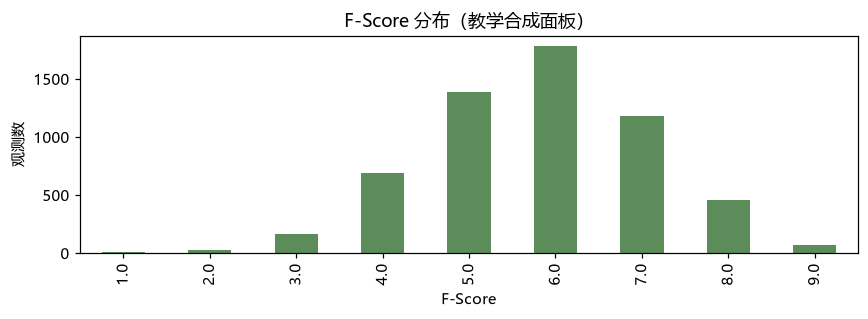

In [2]:
panel = load_ashare_panel()
fund = make_teaching_fundamentals(panel)
fscore = piotroski_f_score(fund)
print('F-Score 面板:', fscore.shape)
print('有效分数范围:', np.nanmin(fscore.values), '~', np.nanmax(fscore.values))
fscore.stack().value_counts().sort_index().plot(kind='bar', figsize=(8, 3), color='#5B8C5A')
plt.title('F-Score 分布（教学合成面板）'); plt.xlabel('F-Score'); plt.ylabel('观测数')
plt.tight_layout(); plt.show()

## 2) 高 F-Score vs 低 F-Score

每月用 t 期 F-Score 分组，持有 t+1 期：

- 高分组：F-Score ≥ 7；
- 低分组：F-Score ≤ 4；
- 多空组合 = 高分组等权收益 − 低分组等权收益。

> 阈值 7/4 是按本示例面板的分布选的；真实研究常用 8~9 分 vs 0~1 分。

In [3]:
ret = panel['ret']
common = fscore.index.intersection(ret.index)
high_rets, low_rets, dates = [], [], []
for t in range(len(common) - 1):
    d, dn = common[t], common[t + 1]
    s = fscore.loc[d].dropna()
    high = s[s >= 7].index
    low = s[s <= 4].index
    if len(high) < 5 or len(low) < 5:
        continue
    high_rets.append(ret.loc[dn, high].mean())
    low_rets.append(ret.loc[dn, low].mean())
    dates.append(dn)
spread = pd.Series(high_rets, index=dates) - pd.Series(low_rets, index=dates)
s = factor_summary(spread)
print(f'高F-Score 月均: {np.mean(high_rets)*100:.3f}%')
print(f'低F-Score 月均: {np.mean(low_rets)*100:.3f}%')
print(f'多空月均: {spread.mean()*100:.3f}%  NW t={s["t_stat"]:.2f}')
print(f'年化: {s["mean_ann"]*100:.2f}%  最大回撤: {s["max_drawdown"]*100:.1f}%')

高F-Score 月均: 1.367%
低F-Score 月均: 1.261%
多空月均: 0.106%  NW t=0.23
年化: 1.27%  最大回撤: -29.6%


> 🔍 **本例不显著**：多空月均约 +0.1%，NW t≈0.23。合成面板没有植入 F-Score 溢价，
> 这个结果是正常的——notebook 演示的是方法，不是保证异象存在。


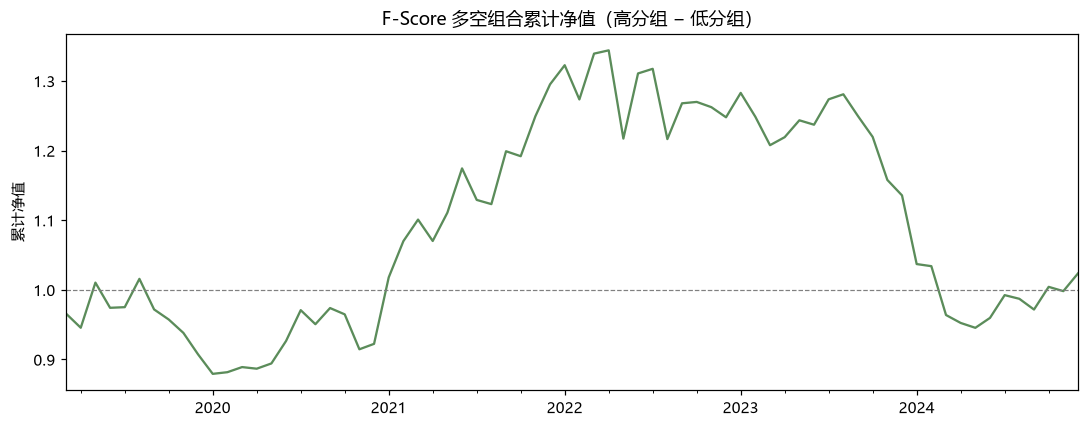

In [4]:
nav = (1 + spread).cumprod()
fig, ax = plt.subplots(figsize=(10, 4))
nav.plot(ax=ax, color='#5B8C5A')
ax.axhline(1, color='gray', lw=.8, ls='--')
ax.set_title('F-Score 多空组合累计净值（高分组 − 低分组）')
ax.set_ylabel('累计净值')
plt.tight_layout(); plt.show()

## ✋ 试一试

1. 把高/低阈值改成 8/2，样本数和多空收益怎么变？
2. 只在高 BM（便宜）股票里做 F-Score 多空，结果会不同吗？
3. 把 F-Score 换成“ROA 最高 − ROA 最低”，和 F-Score 的结果比较。

## ✅ 本节小结

- F-Score 用 9 个财务信号，把“财务健康”变成一个可排序的分数；
- 经典用法：在便宜股里区分“好公司”和“价值陷阱”；
- 分数是工具，不是保证；要结合行业、会计口径、样本外检验；
- 本 notebook 的财务面板是教学合成数据，结果不代表真实公司。

> 下一课：基本面锚定反转——价格离 52 周高点有多远？